Olá, **Gabriela**!

O meu nome é **César Malaguti** e sou o revisor do seu projeto. Comentários coloridos: verde (correto), amarelo (sugestão que não bloqueia) e vermelho (precisa corrigir). Pode me responder em uma caixa azul. Por favor, não mova nem apague os meus comentários.

<div class="alert alert-block alert-danger">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

<b>Comentário geral:</b> Gabriela, obrigado por enviar o projeto! O notebook está executado e bem organizado, com conclusões após cada etapa. A preparação dos dados está correta (padronização dos nomes, tratamento do "tbd", ajuste de tipos, vendas globais), e a análise de ciclo de vida das plataformas, período relevante, correlações e perfis regionais por plataforma está bem encaminhada.

Há dois pontos que precisam ser corrigidos antes da aprovação:

<ul class="text-danger">
  <li><b>Testes de hipótese:</b> faltou formular H0 e H1 e definir o alpha, e a conclusão da primeira hipótese está invertida em relação ao p-valor. Detalhei na seção.</li>
  <li><b>Gêneros por região:</b> você fez as plataformas e o rating por região, mas falta o top de gêneros por região, que também é pedido.</li>
</ul>

Deixei também uma observação em amarelo sobre a conclusão da correlação. Cada ponto está marcado ao longo do notebook. Você está perto!
</div>

<div class="alert alert-block alert-success">
<b>Comentário do revisor v2 (César Malaguti):</b> <a class="tocSkip"></a>

<b>Comentário geral v2:</b> Gabriela, parabéns, seu projeto está aprovado! Você corrigiu os dois pontos que estavam em vermelho:

<ul>
  <li><b>Análise regional:</b> você incluiu o top de gêneros por região, que faltava, completando o perfil de cada mercado (Action liderando na América do Norte e Europa, e Role-Playing com peso no Japão).</li>
  <li><b>Testes de hipótese:</b> agora você formula H0 e H1 por escrito, define o alpha, interpreta o p-valor dentro da própria seção e, principalmente, corrigiu a interpretação da primeira hipótese (p = 0,14 é maior que 0,05, então não rejeitamos a nula).</li>
</ul>

O projeto ficou completo e bem conduzido, da preparação dos dados até as conclusões regionais e os testes. Bom trabalho na reentrega, pode seguir em frente!
</div>

In [39]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

### Leitura do conjunto de dados e análise inicial da estrutura.

In [40]:
df = pd.read_csv('/datasets/games.csv')

df.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [42]:
df.describe()

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


## Nesta etapa serão realizados:

#### Padronização dos nomes das colunas;
#### Conversão de tipos de dados;
#### Tratamento de valores ausentes;
#### Criação da coluna de vendas globais.

In [43]:
df.columns = df.columns.str.lower()

df.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')

# Conversão da coluna user_score

In [44]:
df['user_score'] = df['user_score'].replace('tbd', np.nan)

df['user_score'] = pd.to_numeric(df['user_score'])

In [45]:
df['year_of_release'] = df['year_of_release'].astype('Int64')

# Valores ausentes

In [46]:
df = df.dropna(subset=['name', 'genre'])

In [47]:
# Vendas

In [48]:
df['global_sales'] = (
    df['na_sales']
    + df['eu_sales']
    + df['jp_sales']
    + df['other_sales']
)

df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,global_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Preparação dos dados muito boa! Nomes em minúsculas, "tbd" tratado com `to_numeric`, `year_of_release` como inteiro, remoção das linhas sem nome/gênero e a coluna `global_sales` somando as quatro regiões. Tudo certo.
</div>

# Quantidade de jogos lançados por ano

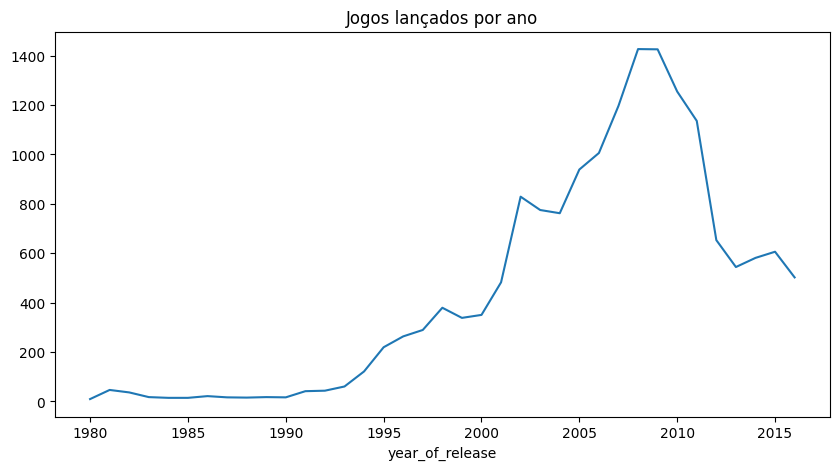

In [49]:
games_per_year = df.groupby('year_of_release')['name'].count()

games_per_year.plot(figsize=(10,5))
plt.title('Jogos lançados por ano')
plt.show()


### Conclusão

#### O número de lançamentos cresce até aproximadamente 2008-2009 e depois apresenta queda.

#### O pico de lançamentos ocorreu entre 2008 e 2009. A partir de 2010 observa-se uma redução gradual na quantidade de jogos lançados, indicando uma mudança no mercado e uma possível consolidação da indústria.


# Plataformas com maiores vendas

In [50]:
platform_sales = (
    df.groupby('platform')['global_sales']
    .sum()
    .sort_values(ascending=False)
)

platform_sales.head(10)

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: global_sales, dtype: float64

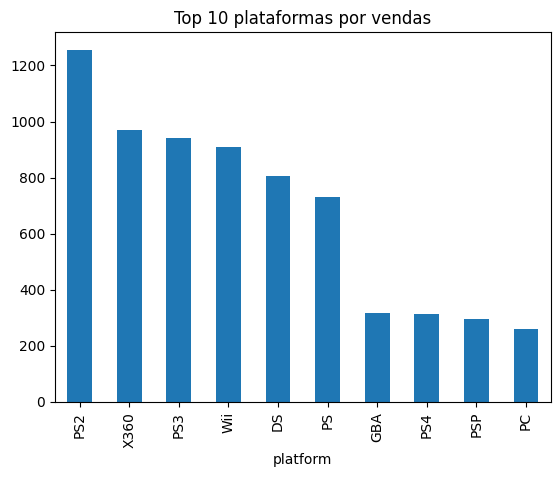

In [51]:
platform_sales.head(10).plot(kind='bar')
plt.title('Top 10 plataformas por vendas')
plt.show()


### Conclusão

#### PS2, Xbox 360, PS3, Wii e DS concentraram os maiores volumes de vendas globais. As plataformas passam por um ciclo de crescimento, com duração aproximada de 7 a 10 anos


# Ciclo de vida das plataformas

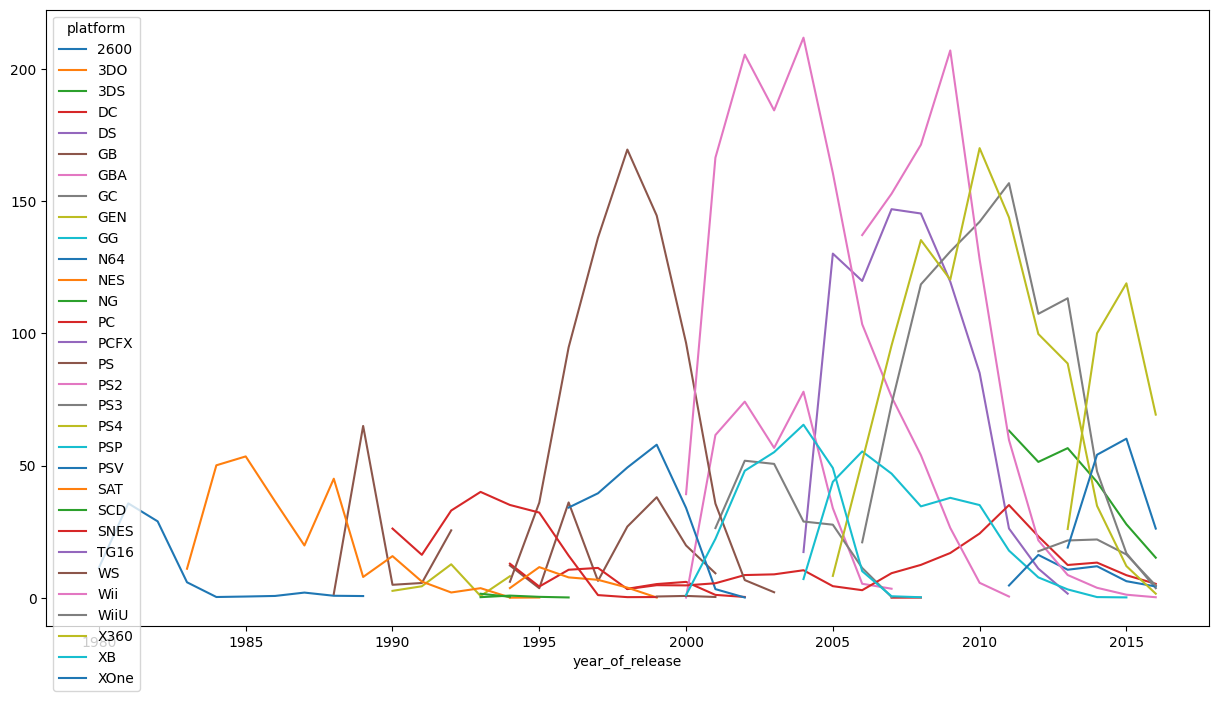

In [52]:
platform_year_sales = (
    df.pivot_table(
        index='year_of_release',
        columns='platform',
        values='global_sales',
        aggfunc='sum'
    )
)

platform_year_sales.plot(figsize=(15,8))
plt.show()

### Conclusão

#### As plataformas possuem um ciclo médio de vida entre 7 e 10 anos.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Boa análise! Você identificou o ciclo de vida das plataformas (7 a 10 anos), justificou o recorte a partir de 2013 para a previsão de 2017 e destacou PS4 e Xbox One como as mais promissoras. Conexão certa entre o histórico e a decisão.
</div>

## Período relevante

#### Para as previsões de 2017, serão utilizados apenas os anos mais recentes.

In [53]:
recent_df = df[df['year_of_release'] >= 2013]

In [54]:

recent_platform_sales = (
    recent_df.groupby('platform')['global_sales']
    .sum()
    .sort_values(ascending=False)
)

recent_platform_sales


platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: global_sales, dtype: float64


### Conclusão

#### PS4 e Xbox One apresentam o maior potencial para 2017.
#### O Nintendo 3DS mantém participação relevante.
#### Já Wii, PSP e DS estão em declínio.


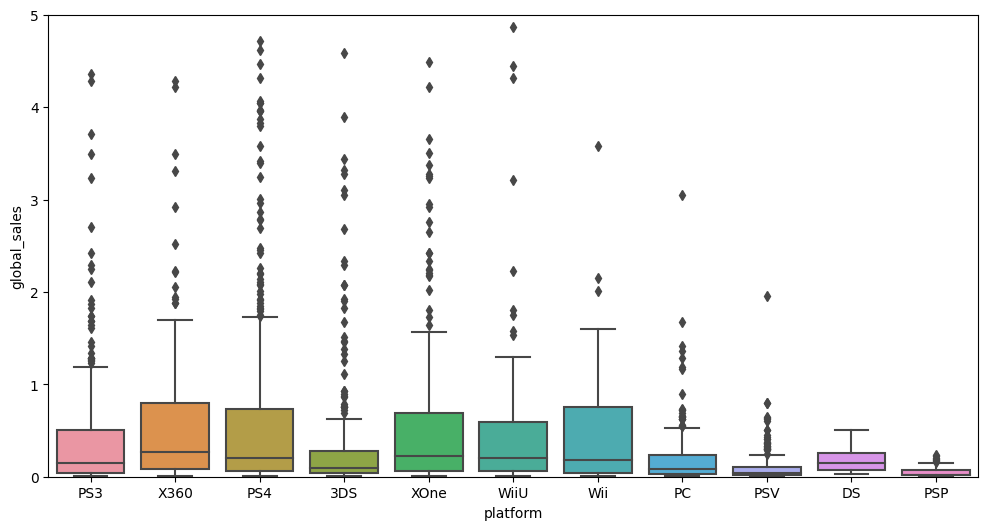

In [55]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=recent_df,
    x='platform',
    y='global_sales'
)

plt.ylim(0,5)
plt.show()

### Conclusão

#### Assimetrico devido à presença de jogos extremamente populares.

## Avaliações x vendas

In [56]:
ps4 = recent_df[recent_df['platform'] == 'PS4']

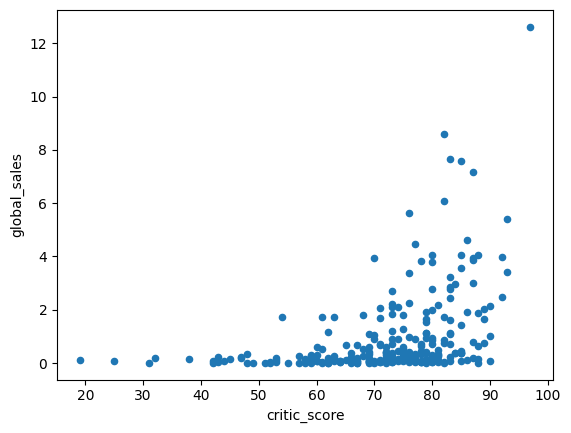

In [57]:
ps4.plot(
    x='critic_score',
    y='global_sales',
    kind='scatter'
)

plt.show()

In [58]:
ps4[['critic_score', 'global_sales']].corr()

,critic_score,global_sales
critic_score,1.000000,0.406568
global_sales,0.406568,1.000000


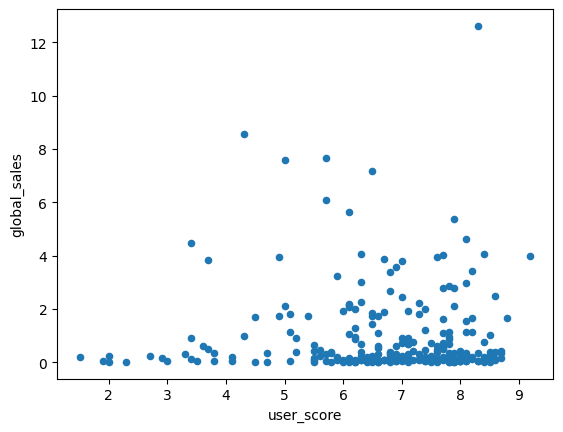

In [59]:
ps4.plot(
    x='user_score',
    y='global_sales',
    kind='scatter'
)

plt.show()

In [60]:
ps4[['user_score', 'global_sales']].corr()

,user_score,global_sales
user_score,1.000000,-0.031957
global_sales,-0.031957,1.000000


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Boa abordagem! Você escolheu uma plataforma popular (PS4), fez os gráficos de dispersão e calculou a correlação de `critic_score` (cerca de 0,41) e de `user_score` (cerca de -0,03) com as vendas. A estrutura está correta.
</div>

### Conclusão

#### As avaliações dos críticos apresentam correlação moderada com as vendas dos jogos, enquanto as avaliações dos usuários apresentam correlação fraca ou praticamente inexistente.



<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Atenção à conclusão desta etapa. O texto ficou confuso e com um exagero: uma correlação em torno de 0,41 é considerada **moderada**, não "forte" (a referência usual é: até 0,3 fraca, 0,3 a 0,7 moderada, acima de 0,7 forte). E a ideia central é que a nota da **crítica** tem mais relação com as vendas do que a nota dos **usuários** (que ficou perto de zero). Curiosamente, na sua Conclusão Geral lá no final você escreveu isso corretamente. Vale alinhar este comentário com aquele, para o notebook ficar coerente.
</div>

## Gêneros

In [61]:
genre_sales = (
    recent_df.groupby('genre')['global_sales']
    .median()
    .sort_values(ascending=False)
)

genre_sales

genre
Shooter         0.450
Sports          0.240
Platform        0.225
Role-Playing    0.125
Fighting        0.125
Racing          0.120
Action          0.110
Simulation      0.100
Misc            0.100
Strategy        0.080
Puzzle          0.060
Adventure       0.030
Name: global_sales, dtype: float64

## Usuários por Região

In [62]:
# América do Norte
na_platforms = (
    recent_df.groupby('platform')['na_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

na_platforms

platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
Name: na_sales, dtype: float64

In [63]:
# Europa
eu_platforms = (
    recent_df.groupby('platform')['eu_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

eu_platforms

platform
PS4     141.09
PS3      67.81
XOne     51.59
X360     42.52
3DS      30.96
Name: eu_sales, dtype: float64

In [64]:
# Japão
jp_platforms = (
    recent_df.groupby('platform')['jp_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

jp_platforms

platform
3DS     67.81
PS3     23.35
PSV     18.59
PS4     15.96
WiiU    10.88
Name: jp_sales, dtype: float64

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Boa! Os perfis regionais por plataforma estão certos (PS4 forte em NA e EU, 3DS dominante no Japão), e o rating ESRB por região também foi calculado. A leitura de que NA e EU se parecem e o Japão é diferente está coerente.
</div>


### Conclusão

#### América do Norte e Europa possuem perfis semelhantes, enquanto o Japão apresenta preferência por plataformas diferentes.


In [65]:
recent_df.groupby('rating')[
    ['na_sales','eu_sales','jp_sales']
].sum()

,na_sales,eu_sales,jp_sales
rating,,,
E,79.05,83.36,15.14
E10+,54.24,42.69,5.89
M,165.21,145.32,14.11
T,49.79,41.95,20.59


### Gêneros

In [66]:
# América do Norte
na_genres = (
    recent_df.groupby('genre')['na_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

na_genres

genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Name: na_sales, dtype: float64

In [67]:
# Europa
eu_genres = (
    recent_df.groupby('genre')['eu_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

eu_genres

genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Name: eu_sales, dtype: float64

In [68]:
# Japão
jp_genres = (
    recent_df.groupby('genre')['jp_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

jp_genres

genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64

### Conclusão

#### Action lidera as vendas na América do Norte e Europa, enquanto Role-Playing ocupa a primeira posição no Japão. Isso evidencia diferenças nas preferências dos jogadores entre os mercados ocidentais e o mercado japonês.

<div class="alert alert-block alert-danger">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Aqui falta uma parte da análise regional. Você apresentou o top de **plataformas** por região (América do Norte, Europa, Japão) e o impacto do **rating** por região, o que está ótimo. Mas o projeto também pede o top de **gêneros por região**, que não aparece.

É o mesmo tipo de agrupamento que você já fez para as plataformas, só trocando a coluna: para cada região, agrupar por `genre` e somar as vendas daquela região, por exemplo:

```python
recent_df.groupby('genre')['na_sales'].sum().sort_values(ascending=False).head(5)
```

E repetir para `eu_sales` e `jp_sales`. Isso costuma revelar diferenças culturais importantes (por exemplo, o peso do gênero Role-Playing no Japão). Inclua essa análise para completar o perfil de cada região.
</div>

<div class="alert alert-block alert-success">
<b>Comentário do revisor v2 (César Malaguti):</b> <a class="tocSkip"></a>

Corrigido! Você adicionou o top de gêneros por região (América do Norte, Europa e Japão), que era a parte que faltava. Agora o perfil regional está completo, com plataformas, rating e gêneros, e dá para ver bem a diferença cultural (o Role-Playing forte no Japão). Boa!
</div>

## Testes de Hipóteses

### Objetivo: verificar se as avaliações médias dos usuários das plataformas Xbox One e PC são iguais

#### Hipótese nula (H₀): são iguais

####  Hipótese alternativa (H₁): são diferentes

#### Nível de significância: α = 0,05

In [69]:
# 1

xone = recent_df[
    recent_df['platform'] == 'XOne'
]['user_score'].dropna()

pc = recent_df[
    recent_df['platform'] == 'PC'
]['user_score'].dropna()

stats.ttest_ind(xone, pc)

Ttest_indResult(statistic=1.4788255981357277, pvalue=0.14012658403611647)

### Conclusão

#### -valor obtido foi 0,1401, então não há evidências suficientes para afirmar que as avaliações médias dos usuários das plataformas Xbox One e PC sejam diferentes

### Hipótese 2

#### Objetivo: verificar se as avaliações médias dos usuários dos gêneros Action e Sports são iguais

#### Hipótese nula (H₀): são iguais

#### Hipótese alternativa (H₁): são diferentes

#### Nível de significância: α = 0,05

In [70]:
# 2

action = recent_df[
    recent_df['genre'] == 'Action'
]['user_score'].dropna()

sports = recent_df[
    recent_df['genre'] == 'Sports'
]['user_score'].dropna()

stats.ttest_ind(action, sports)

Ttest_indResult(statistic=11.535100577928208, pvalue=1.0517832389140023e-27)

### Conclusão 

#### p-valor foi aproximadamente zero e isso siignifica que as médias dos usuários dos gêneros Action e Sports são diferentes

<div class="alert alert-block alert-danger">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Esta seção precisa de ajustes. Três pontos:

1. <b>Formule H0 e H1 por escrito</b> (em uma célula de texto) antes de cada teste, e <b>defina o alpha</b> (normalmente 0,05). Hoje os testes rodam direto, sem deixar claro o que está sendo testado nem o critério de decisão.

2. <b>Interprete o p-valor e conclua dentro da própria seção</b> (e não só lá na conclusão geral), comparando o p-valor com o alpha.

3. <b>Atenção à conclusão da primeira hipótese, que está invertida.</b> O teste de XOne vs PC deu <b>p = 0,14</b>, que é <b>maior</b> que 0,05. Quando o p-valor é maior que o alpha, nós <b>não rejeitamos</b> a hipótese nula (ou seja, não há evidência de diferença significativa entre as notas). Mas na sua Conclusão Geral você escreveu que "a primeira hipótese foi Rejeitada", que é o contrário do que o p-valor indica. A segunda hipótese (Action vs Sports, p praticamente zero) essa sim é rejeitada, e você acertou. Corrija a interpretação da primeira.

Dica adicional (opcional): no `ttest_ind`, vale usar `equal_var=False` quando não dá para assumir que as variâncias dos dois grupos são iguais.
</div>

<div class="alert alert-block alert-success">
<b>Comentário do revisor v2 (César Malaguti):</b> <a class="tocSkip"></a>

Corrigido, e bem feito! Os três ajustes que eu havia pedido estão resolvidos:

1. Você formulou H0 e H1 por escrito e definiu o alpha (0,05) antes de cada teste.
2. Interpretou o p-valor dentro da própria seção, comparando com o alpha.
3. A interpretação da primeira hipótese (XOne vs PC, p = 0,14) agora está certa: como o p-valor é maior que 0,05, não rejeitamos a hipótese nula, ou seja, não há evidência de diferença significativa. E a segunda (Action vs Sports, p quase zero) é rejeitada, como você apontou.

Seção de testes de hipótese bem fechada agora.
</div>

### Conclusão Geral

#### Os dados indicam que:

##### As plataformas possuem ciclo de vida aproximado de 7 a 10 anos;
##### PS4 e Xbox One estão entre as plataformas mais promissoras para 2017;
##### Avaliações de críticos possuem maior relação com vendas do que avaliações de usuários;
##### Gêneros Action e Shooter apresentam maior potencial comercial;
##### Existem diferenças relevantes entre os mercados da América do Norte, Europa e Japão;
##### A primeira hipótese não foi rejeitada;
##### A segunda hipótese foi rejeitada.